# TP #1 — Analyse en composantes principales (ACP) avec Python
**Apprentissage Automatique Avancé** — Prof. Abdelouahab Moussaoui

Ce notebook couvre :
- **Partie 3, Exercice 1** : ACP de données générées (déformation + rotation)
- **Partie 3, Exercice 2** : ACP sur les données « feuilles » (`leaf.csv`)
- **Partie 2, Exercice 2** : ACP sur le jeu de données Iris (version Python)

> La Partie 2, Exercice 1 (décathlon, `FactoMineR`) se fait en R et n'est pas incluse ici.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from sklearn.decomposition import PCA
from sklearn import preprocessing

np.set_printoptions(precision=4, suppress=True)
np.random.seed(42)   # reproductibilité

---
# Partie 3 — Exercice 1 : ACP de données générées
## Génération et visualisation de 500 vecteurs gaussiens 3D

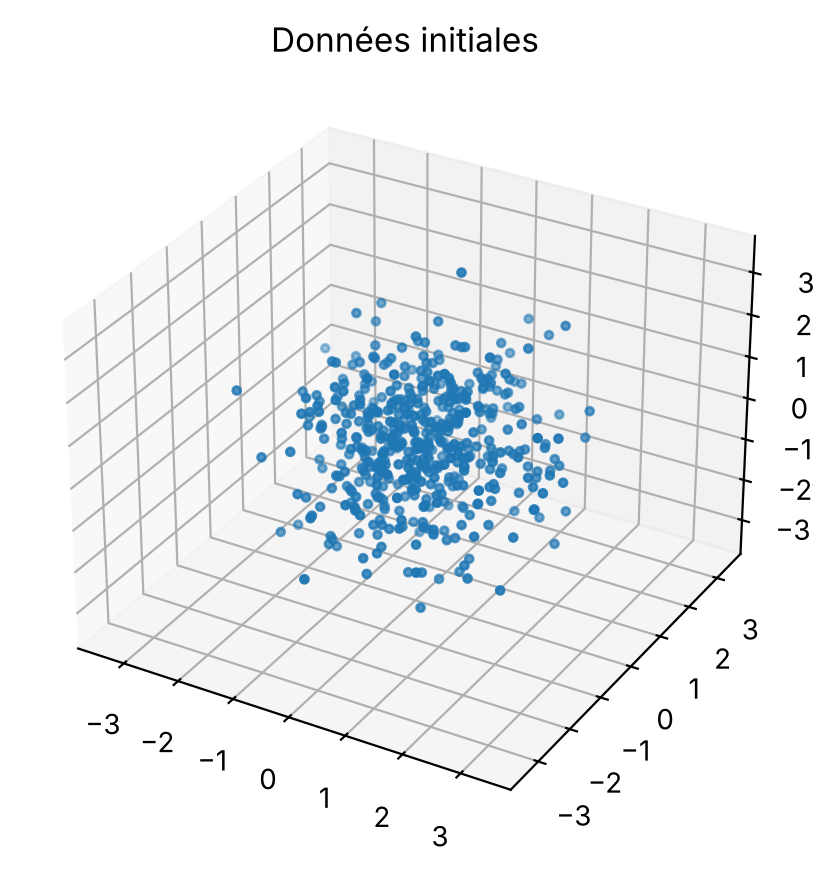

In [2]:
rndn3d = np.random.randn(500, 3)

def scatter3d(X, title):
    fig = plt.figure(figsize=(6, 5))
    ax = fig.add_subplot(111, projection='3d')
    ax.scatter(X[:, 0], X[:, 1], X[:, 2], s=8)
    ax.set_title(title)
    # même échelle sur les 3 axes pour ne pas fausser la forme du nuage
    lim = np.abs(X).max()
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_zlim(-lim, lim)
    plt.show()

scatter3d(rndn3d, "Données initiales")

In [3]:
pca = PCA(n_components=3)
pca.fit(rndn3d)

print("Pourcentage de variance expliquée :")
print(pca.explained_variance_ratio_)
print("Composantes principales :")
print(pca.components_)

Pourcentage de variance expliquée :
[0.3654 0.3387 0.296 ]
Composantes principales :
[[-0.0277  0.4194  0.9074]
 [-0.2975  0.8631 -0.4081]
 [ 0.9543  0.2812 -0.1008]]


## Question 1 — Un autre tableau `randn(500,3)`

In [4]:
rndn3d_bis = np.random.randn(500, 3)
pca_bis = PCA(n_components=3).fit(rndn3d_bis)

print("Jeu 1 — variance expliquée :", pca.explained_variance_ratio_)
print("Jeu 2 — variance expliquée :", pca_bis.explained_variance_ratio_)
print("\nJeu 1 — composantes :\n", pca.components_)
print("\nJeu 2 — composantes :\n", pca_bis.components_)

Jeu 1 — variance expliquée : [0.3654 0.3387 0.296 ]
Jeu 2 — variance expliquée : [0.376  0.3316 0.2924]

Jeu 1 — composantes :
 [[-0.0277  0.4194  0.9074]
 [-0.2975  0.8631 -0.4081]
 [ 0.9543  0.2812 -0.1008]]

Jeu 2 — composantes :
 [[-0.588   0.7651  0.2623]
 [ 0.7511  0.6369 -0.174 ]
 [ 0.3002 -0.0947  0.9492]]


**Constat.** Dans les deux tirages les trois valeurs propres sont voisines (chaque axe explique environ **un tiers** de la variance) : le nuage est quasi **sphérique**, il n'existe aucune direction privilégiée. Les écarts avec 1/3 sont dus uniquement au **bruit d'échantillonnage** (n = 500).

Les vecteurs propres, eux, **diffèrent d'un tirage à l'autre** : quand les valeurs propres sont (presque) égales, les axes principaux ne sont pas bien définis (n'importe quelle base orthonormée convient théoriquement), donc l'algorithme retourne une base arbitraire, dictée par le bruit. L'ACP n'a rien à « découvrir » sur des données isotropes.

## Question 2 — Déformation et rotation du nuage `rndn3d`

Matrice de déformation s1 :
 [[1. 0. 0.]
 [0. 2. 0.]
 [0. 0. 5.]]
Matrice de rotation R :
 [[ 0.7071 -0.6124  0.3536]
 [ 0.7071  0.6124 -0.3536]
 [ 0.      0.5     0.866 ]]
R orthogonale ? R^T R = I : True


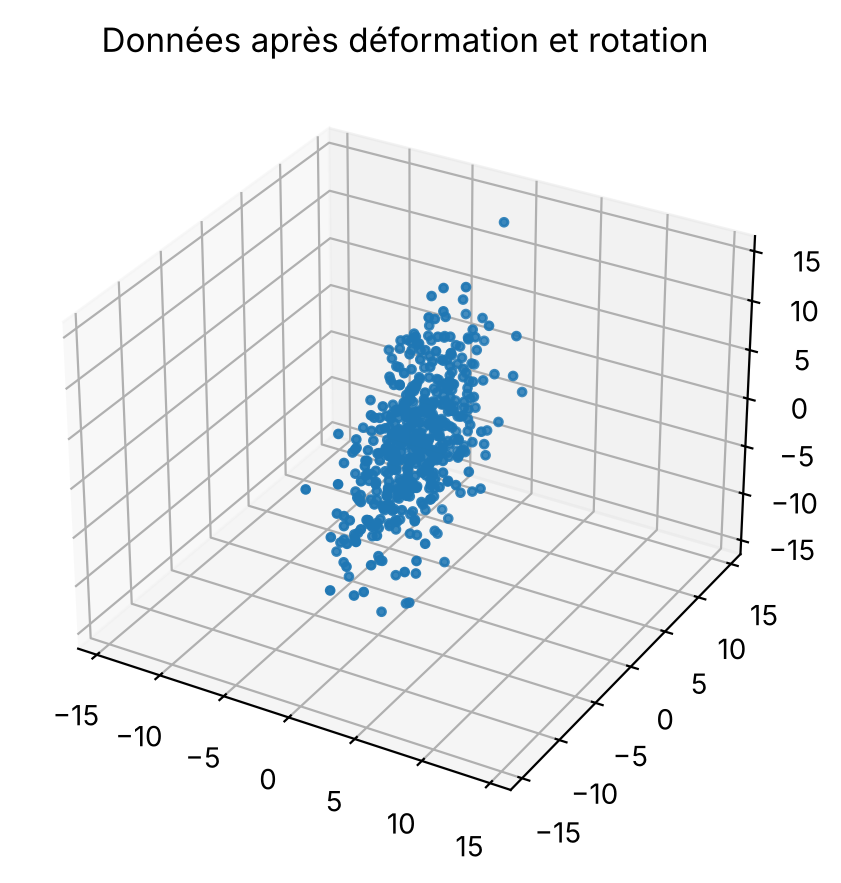

In [5]:
# Déformation (étirement) : variances relatives 1 : 4 : 25
s1 = np.diag([1.0, 2.0, 5.0])

# Rotation d'angle pi/4 autour de l'axe z, puis pi/6 autour de l'axe x
def rot_z(t):
    c, s = np.cos(t), np.sin(t)
    return np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])

def rot_x(t):
    c, s = np.cos(t), np.sin(t)
    return np.array([[1, 0, 0], [0, c, -s], [0, s, c]])

R = rot_z(np.pi / 4) @ rot_x(np.pi / 6)

print("Matrice de déformation s1 :\n", s1)
print("Matrice de rotation R :\n", R)
print("R orthogonale ? R^T R = I :", np.allclose(R.T @ R, np.eye(3)))

rndef = rndn3d @ s1 @ R
scatter3d(rndef, "Données après déformation et rotation")

## Question 3 — ACP sur le nuage déformé / lien avec `s1`

In [6]:
pca_def = PCA(n_components=3).fit(rndef)

print("Variance expliquée (%)        :", pca_def.explained_variance_ratio_)
print("Valeurs propres               :", pca_def.explained_variance_)
print("Écarts-types (racine val.pr.) :", np.sqrt(pca_def.explained_variance_))
print("Diagonale de s1               :", np.diag(s1))
print()
print("Rapports des écarts-types      :", np.sqrt(pca_def.explained_variance_) / np.sqrt(pca_def.explained_variance_)[-1])
print("Rapports des valeurs propres   :", pca_def.explained_variance_ / pca_def.explained_variance_[-1])
print("Carrés de la diagonale de s1   :", np.sort(np.diag(s1) ** 2)[::-1] / 1.0)

Variance expliquée (%)        : [0.8445 0.1274 0.0281]
Valeurs propres               : [26.4386  3.9883  0.8783]
Écarts-types (racine val.pr.) : [5.1418 1.9971 0.9372]
Diagonale de s1               : [1. 2. 5.]

Rapports des écarts-types      : [5.4866 2.131  1.    ]
Rapports des valeurs propres   : [30.1031  4.541   1.    ]
Carrés de la diagonale de s1   : [25.  4.  1.]


**Constat.** Contrairement aux données gaussiennes isotropes, l'ACP met ici en évidence **une structure très nette** : une première composante porte environ 84 % de la variance, une deuxième ≈ 13 % et la troisième ≈ 3 %.

**Lien avec `s1`.** La rotation `R` est orthogonale : elle ne modifie ni les distances ni les valeurs propres, elle change seulement l'orientation des axes. Les valeurs propres sont donc déterminées par la déformation seule. Comme les données de départ ont une variance ≈ 1 par axe, une dilatation de facteur `d` multiplie la **variance** par `d²` :

$$\lambda_i \approx d_i^2 \quad\Rightarrow\quad \sqrt{\lambda_i}\approx d_i$$

Ici `diag(s1) = (1, 2, 5)` donne des valeurs propres de l'ordre de **(25, 4, 1)** (on observe ≈ 26, 4 et 0,9) : le **rapport des écarts-types** est voisin du rapport des éléments de la diagonale (≈ 5 : 2 : 1), et le **rapport des valeurs propres** de celui de leurs carrés. L'égalité n'est qu'approchée à cause de l'échantillonnage (n = 500), surtout pour la plus petite valeur propre qui sert de référence. Les vecteurs propres, eux, redonnent les axes déformés puis tournés (les colonnes de `R`, au signe près).

In [7]:
# Vérification : les axes principaux retrouvés correspondent aux lignes de R
# (au signe près), classées par ordre décroissant de variance
print("Composantes principales (lignes) :\n", pca_def.components_)
print("\nLignes de R (axe z déformé x5 en premier) :\n", R[::-1])
print("\n|cos| entre axes retrouvés et axes de R :")
print(np.abs(pca_def.components_ @ R[::-1].T))

Composantes principales (lignes) :
 [[ 0.0119  0.5079  0.8614]
 [ 0.691   0.6185 -0.3742]
 [ 0.7228 -0.5996  0.3436]]

Lignes de R (axe z déformé x5 en premier) :
 [[ 0.      0.5     0.866 ]
 [ 0.7071  0.6124 -0.3536]
 [ 0.7071 -0.6124  0.3536]]

|cos| entre axes retrouvés et axes de R :
[[0.9999 0.0149 0.0019]
 [0.0148 0.9996 0.0225]
 [0.0023 0.0224 0.9997]]


## Question 4 — Nouveau jeu de données, mêmes matrices de transformation

In [8]:
rndn3d_new = np.random.randn(500, 3)
rndef_new = rndn3d_new @ s1 @ R
pca_def_new = PCA(n_components=3).fit(rndef_new)

print("Variance expliquée  — jeu 1 :", pca_def.explained_variance_ratio_)
print("Variance expliquée  — jeu 2 :", pca_def_new.explained_variance_ratio_)
print("Valeurs propres     — jeu 1 :", pca_def.explained_variance_)
print("Valeurs propres     — jeu 2 :", pca_def_new.explained_variance_)
print("\n|cos| entre les axes des deux ACP (diagonale ≈ 1 => mêmes axes) :")
print(np.abs(pca_def.components_ @ pca_def_new.components_.T))

Variance expliquée  — jeu 1 : [0.8445 0.1274 0.0281]
Variance expliquée  — jeu 2 : [0.8355 0.1309 0.0336]
Valeurs propres     — jeu 1 : [26.4386  3.9883  0.8783]
Valeurs propres     — jeu 2 : [25.8021  4.0416  1.0379]

|cos| entre les axes des deux ACP (diagonale ≈ 1 => mêmes axes) :
[[0.9988 0.0464 0.014 ]
 [0.0465 0.9989 0.0037]
 [0.0138 0.0044 0.9999]]


**Constat.** Avec les mêmes matrices `s1` et `R`, on obtient des résultats **quasi identiques** : mêmes proportions de variance (≈ 84 / 13 / 3 %), et surtout **mêmes axes principaux** (|cos| ≈ 1 sur la diagonale). Les petites différences viennent de l'échantillonnage.

**Explication.** Contrairement au cas isotrope (Q1), les valeurs propres sont ici bien séparées, donc les axes principaux sont **stables** : ils reflètent la structure géométrique imposée par la transformation, pas le bruit. L'ACP est reproductible dès que les valeurs propres sont distinctes.

---
# Partie 3 — Exercice 2 : ACP sur les données « feuilles »
Source : UCI *Leaf Data Set*. Le fichier `leaf.csv` fourni contient une **ligne d'en-tête** (`label,a,b,...,o`), il faut donc ignorer la première ligne au chargement (`skiprows=1`).

Colonnes : 0 = classe de l'espèce (30 classes présentes), 1 = numéro de spécimen, 2 à 15 = 14 descripteurs de forme et de texture.

In [9]:
leaf = np.loadtxt('leaf.csv', delimiter=',', skiprows=1)
print("Dimensions :", leaf.shape)
print("Nombre de classes :", np.unique(leaf[:, 0]).size)
print(leaf[:2, :])

Dimensions : (340, 16)
Nombre de classes : 30
[[1.     1.     0.7269 1.4742 0.324  0.9853 1.     0.8359 0.0047 0.0039
  0.0478 0.128  0.0161 0.0052 0.0003 1.1756]
 [1.     2.     0.7417 1.5257 0.3612 0.9815 0.9982 0.7987 0.0052 0.005
  0.0242 0.0905 0.0081 0.0027 0.0001 0.6966]]


Variance expliquée : [0.4059 0.2996 0.1501 0.0525 0.0313 0.0278 0.0122 0.0081 0.0052 0.0032
 0.0018 0.0013 0.0009 0.    ]
Cumul              : [0.4059 0.7055 0.8557 0.9082 0.9395 0.9673 0.9795 0.9876 0.9929 0.9961
 0.9979 0.9991 1.     1.    ]
Valeurs propres > 1 (critère de Kaiser) : 3


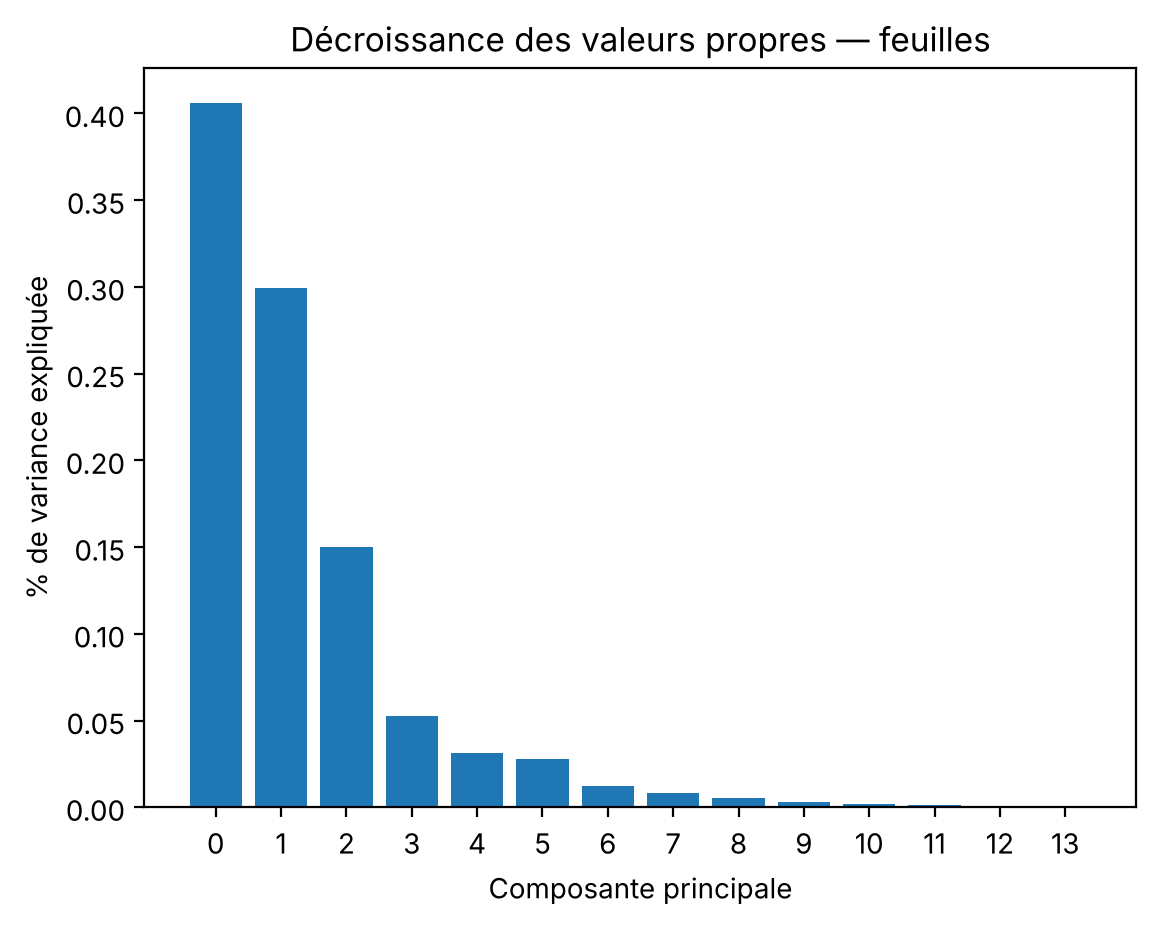

In [10]:
leafN = preprocessing.scale(leaf[:, 2:])   # centrage-réduction des 14 descripteurs
pca_leaf = PCA()
pca_leaf.fit(leafN)

ratios = pca_leaf.explained_variance_ratio_
print("Variance expliquée :", ratios)
print("Cumul              :", np.cumsum(ratios))
print("Valeurs propres > 1 (critère de Kaiser) :", (pca_leaf.explained_variance_ > 1).sum())

plt.bar(range(len(ratios)), ratios)
plt.xticks(range(len(ratios)))
plt.xlabel("Composante principale")
plt.ylabel("% de variance expliquée")
plt.title("Décroissance des valeurs propres — feuilles")
plt.show()

**Lecture.** Les variables sont standardisées (ACP normée). La variance se concentre sur peu d'axes : PC1 ≈ 41 %, PC2 ≈ 30 %, PC3 ≈ 15 %, soit **≈ 86 % cumulés sur les 3 premières composantes**. Le critère de Kaiser (valeurs propres > 1) conserve aussi **3 axes**, et l'éboulis montre une chute nette après la troisième. On retient donc 3 composantes, ce qui justifie la visualisation 3D demandée.

## Question 1 — Projection sur les 3 premiers axes principaux

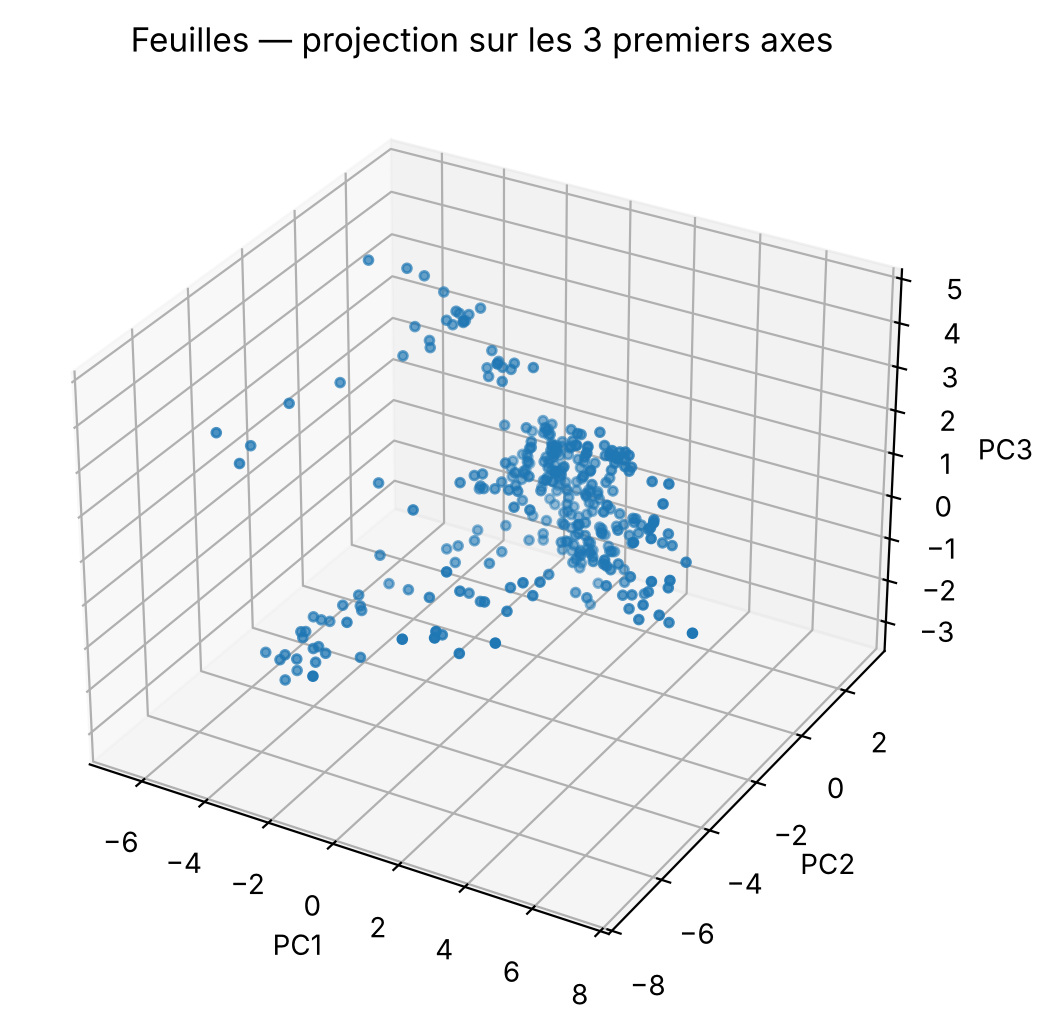

In [11]:
proj = pca_leaf.transform(leafN)[:, :3]

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(proj[:, 0], proj[:, 1], proj[:, 2], s=10)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3")
ax.set_title("Feuilles — projection sur les 3 premiers axes")
plt.show()

## Question 2 — Même projection, colorée par classe

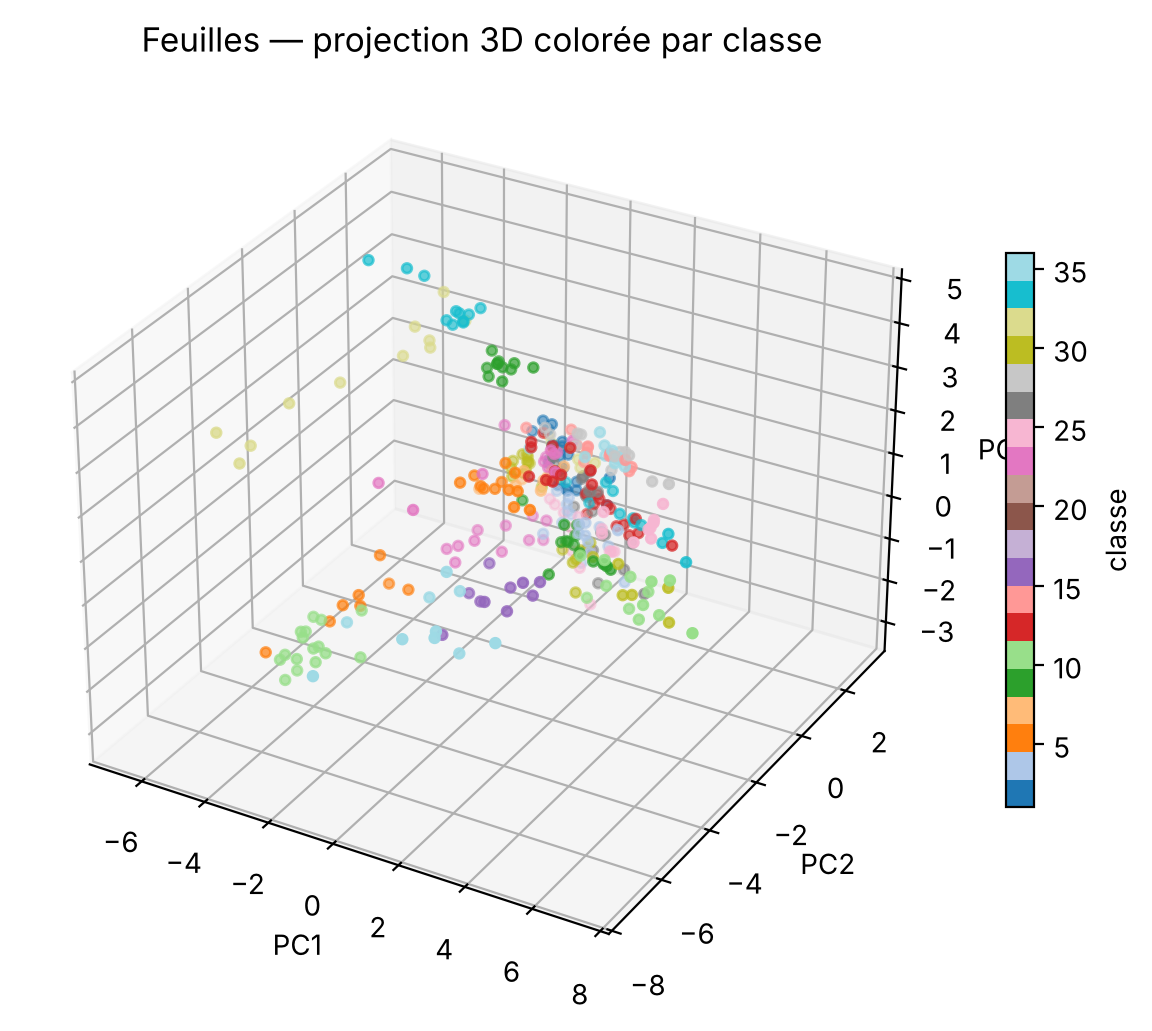

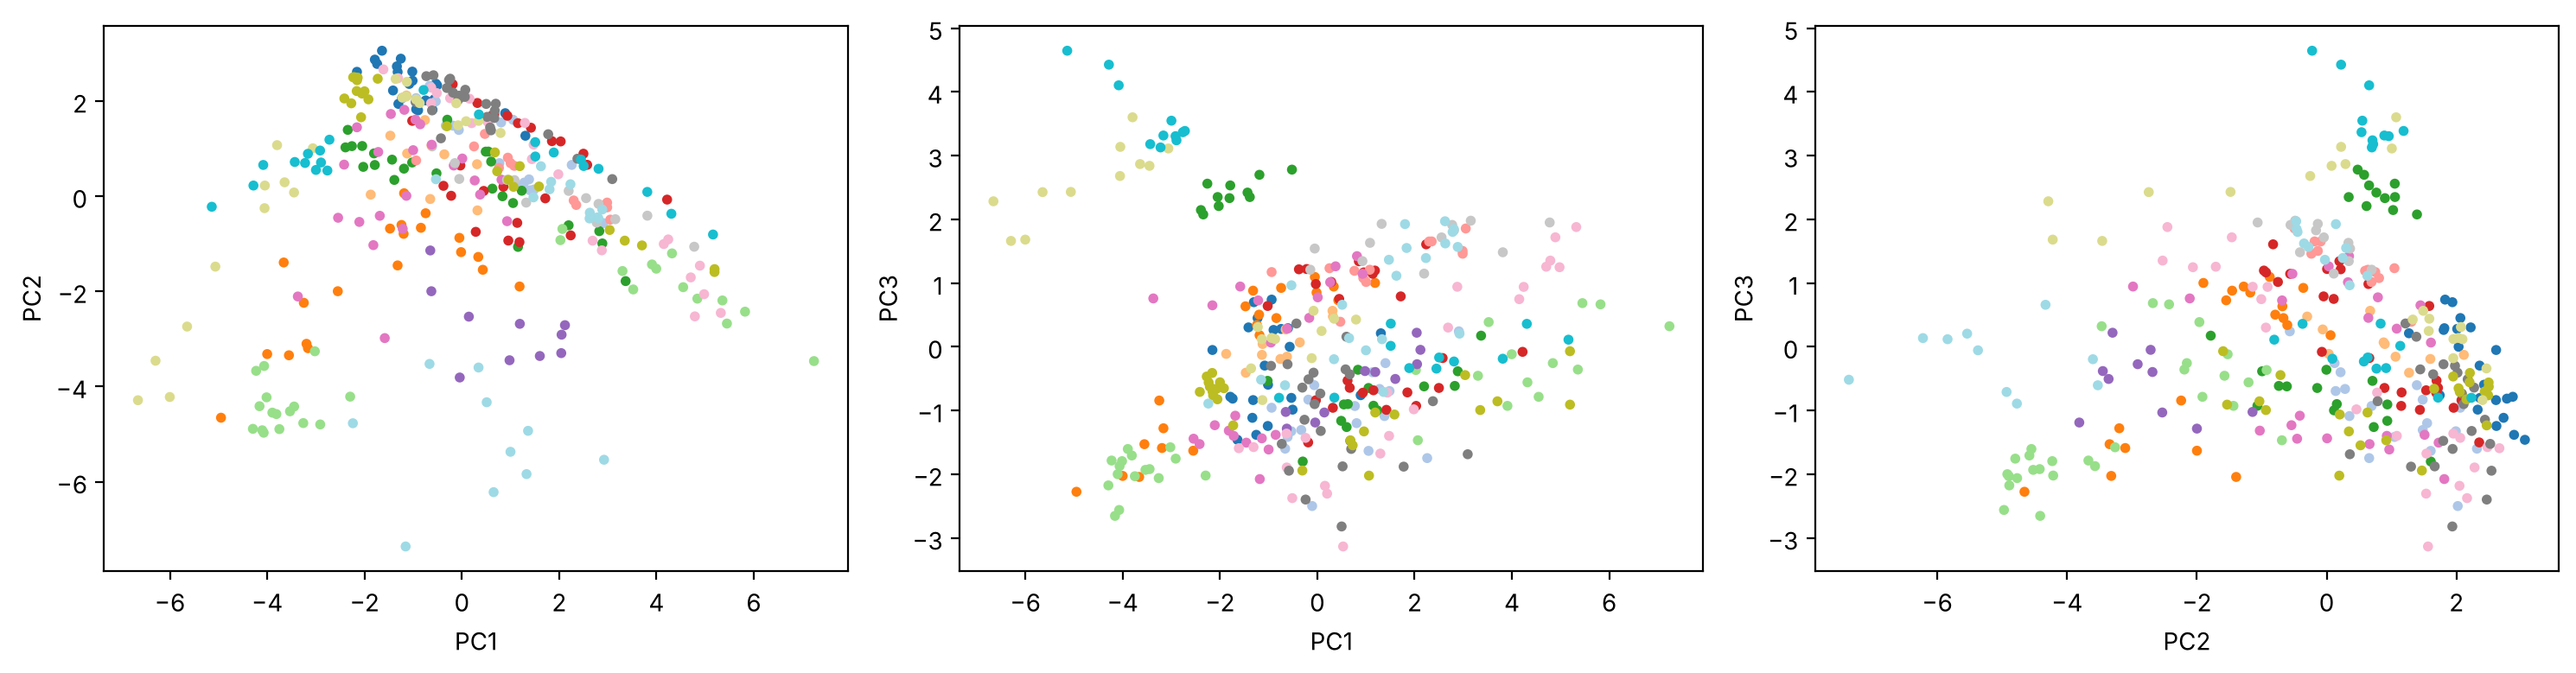

In [12]:
labels = leaf[:, 0]

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(proj[:, 0], proj[:, 1], proj[:, 2], c=labels, cmap='tab20', s=12)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3")
ax.set_title("Feuilles — projection 3D colorée par classe")
fig.colorbar(sc, ax=ax, shrink=0.6, label="classe")
plt.show()

# Vue 2D complémentaire, souvent plus lisible que la 3D
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for a, (i, j) in zip(axes, [(0, 1), (0, 2), (1, 2)]):
    a.scatter(proj[:, i], proj[:, j], c=labels, cmap='tab20', s=10)
    a.set_xlabel(f"PC{i+1}"); a.set_ylabel(f"PC{j+1}")
plt.tight_layout(); plt.show()

**Interprétation.** Avec 340 feuilles réparties en 30 classes, la coloration montre que **quelques espèces** forment des groupes compacts et isolés en périphérie du nuage (visibles surtout dans les plans PC1×PC3 et PC2×PC3), tandis que **la majorité des classes se chevauchent fortement** au centre. L'ACP est **non supervisée** : elle maximise la variance globale, pas la séparation entre classes. Elle donne donc une bonne vue d'ensemble, mais elle ne suffit pas à discriminer les 30 espèces ; pour cela il faudrait un classifieur (k-NN, SVM, forêt aléatoire) ou une méthode supervisée comme l'**analyse discriminante linéaire (LDA)**.

---
# Partie 2 — Exercice 2 : ACP sur Iris (version Python)
Les 3 questions du sujet : (1) construire la matrice `donnees` (150 × 4), (2) ACP + qualité de la représentation + interprétation des 2 premiers axes, (3) caractéristiques discriminantes entre les 3 espèces ?

In [13]:
from sklearn.datasets import load_iris
iris = load_iris()
donnees = iris.data                       # 150 x 4
especes = iris.target
noms_var = ['Long. sépale', 'Larg. sépale', 'Long. pétale', 'Larg. pétale']
print(donnees.shape)

(150, 4)


In [14]:
Z = preprocessing.scale(donnees)          # ACP normée
pca_iris = PCA().fit(Z)
scores = pca_iris.transform(Z)

print("Valeurs propres :", pca_iris.explained_variance_)
print("% variance      :", pca_iris.explained_variance_ratio_ * 100)
print("Cumul           :", np.cumsum(pca_iris.explained_variance_ratio_) * 100)

# Saturations = corrélations variables / composantes
sat = pca_iris.components_.T * np.sqrt(pca_iris.explained_variance_)
print("\nSaturations (corrélations variable-axe) :")
for n, s in zip(noms_var, sat):
    print(f"  {n:14s}", s)

Valeurs propres : [2.9381 0.9202 0.1477 0.0209]
% variance      : [72.9624 22.8508  3.6689  0.5179]
Cumul           : [ 72.9624  95.8132  99.4821 100.    ]

Saturations (corrélations variable-axe) :
  Long. sépale   [ 0.8932  0.362   0.2766 -0.0377]
  Larg. sépale   [-0.4617  0.8857 -0.0939  0.0178]
  Long. pétale   [ 0.9949  0.0235 -0.0546  0.1157]
  Larg. pétale   [ 0.9682  0.0642 -0.2438 -0.0756]


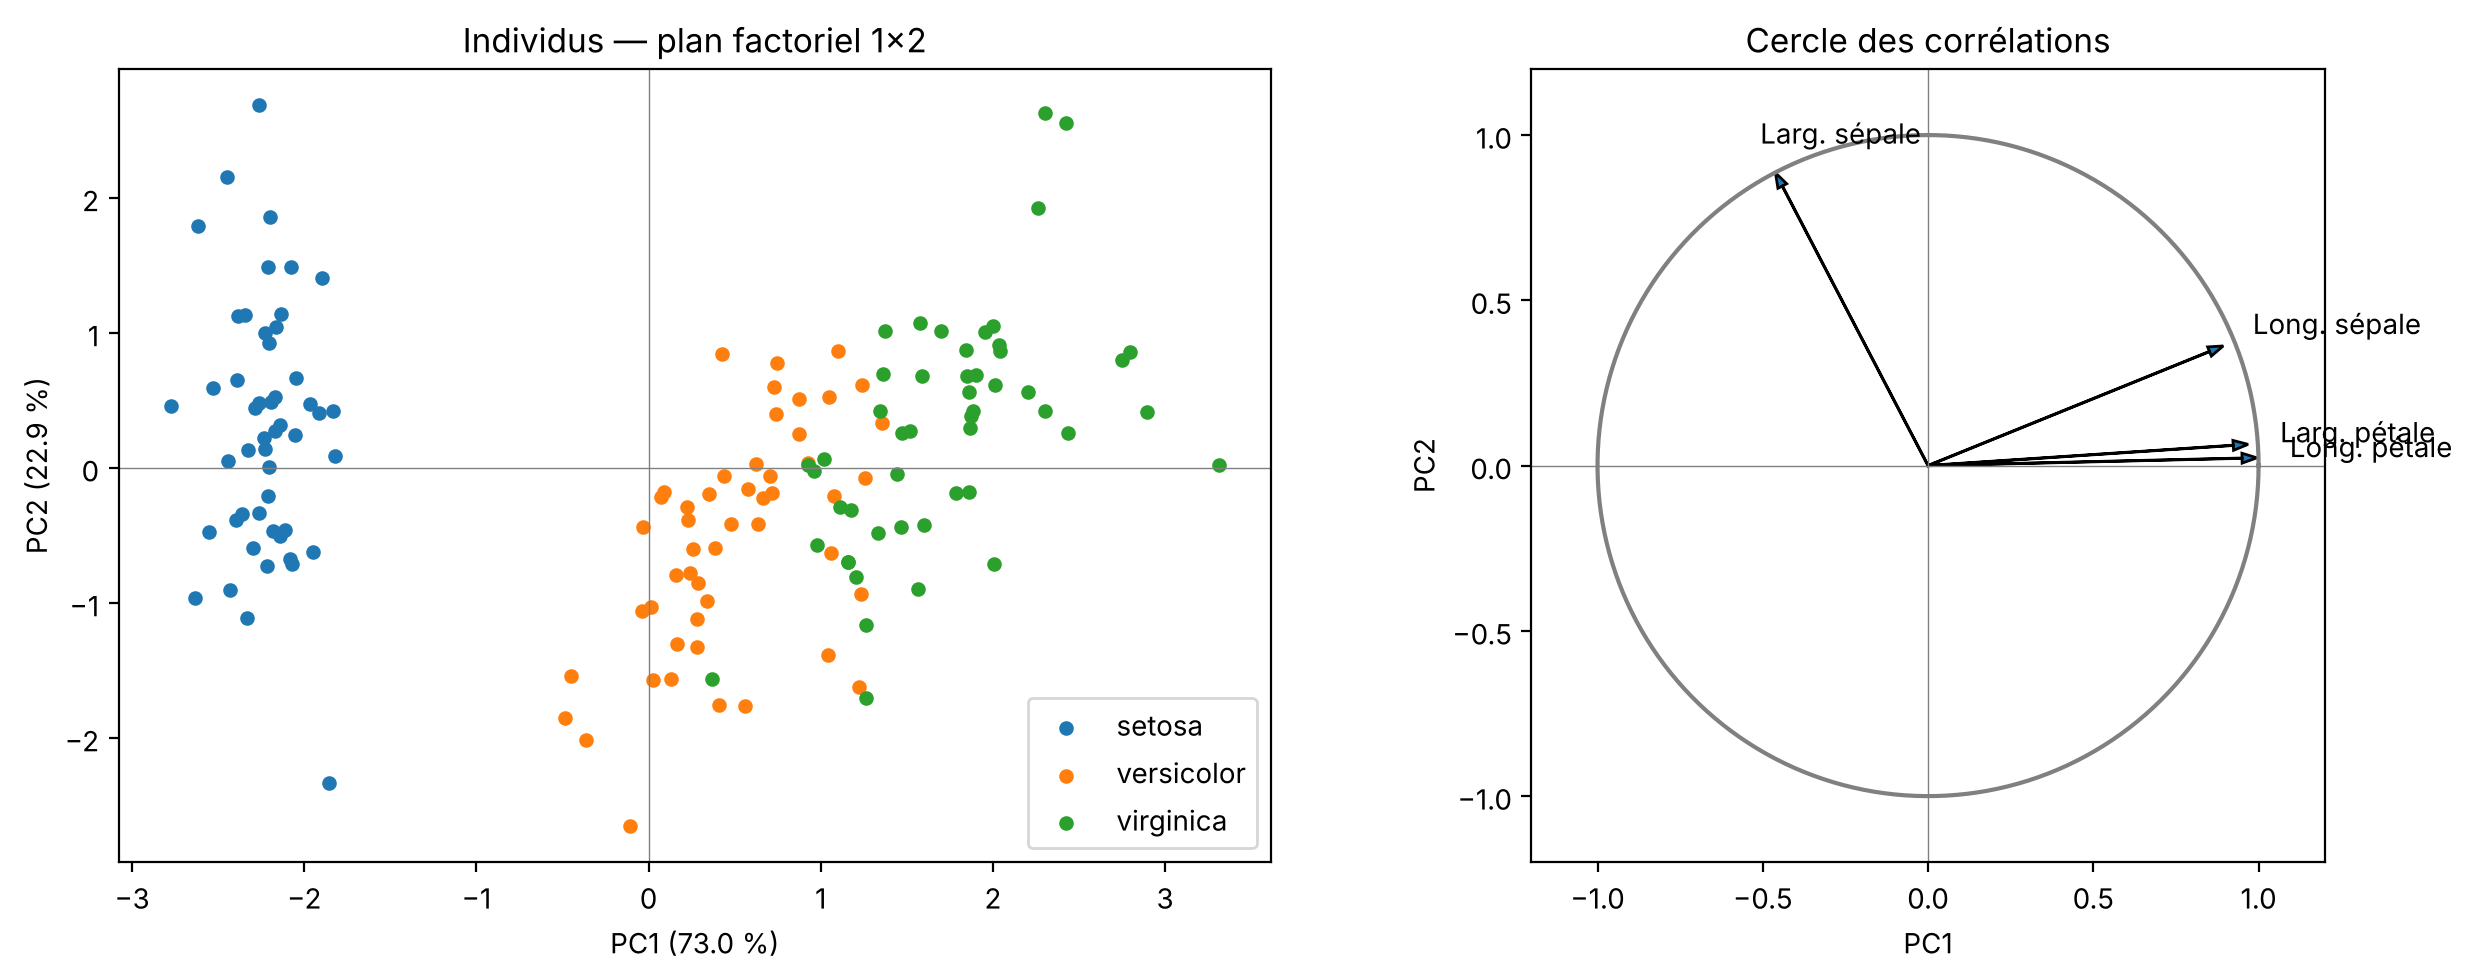

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plan des individus
for k, nom in enumerate(iris.target_names):
    m = especes == k
    axes[0].scatter(scores[m, 0], scores[m, 1], label=nom, s=18)
axes[0].set_xlabel(f"PC1 ({pca_iris.explained_variance_ratio_[0]*100:.1f} %)")
axes[0].set_ylabel(f"PC2 ({pca_iris.explained_variance_ratio_[1]*100:.1f} %)")
axes[0].set_title("Individus — plan factoriel 1×2")
axes[0].axhline(0, c='grey', lw=.5); axes[0].axvline(0, c='grey', lw=.5)
axes[0].legend()

# Cercle des corrélations
t = np.linspace(0, 2*np.pi, 200)
axes[1].plot(np.cos(t), np.sin(t), c='grey')
for n, s in zip(noms_var, sat):
    axes[1].arrow(0, 0, s[0], s[1], head_width=0.03, length_includes_head=True)
    axes[1].text(s[0]*1.1, s[1]*1.1, n)
axes[1].axhline(0, c='grey', lw=.5); axes[1].axvline(0, c='grey', lw=.5)
axes[1].set_xlim(-1.2, 1.2); axes[1].set_ylim(-1.2, 1.2); axes[1].set_aspect('equal')
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
axes[1].set_title("Cercle des corrélations")
plt.tight_layout(); plt.show()

**Qualité de la représentation.** Les deux premiers axes expliquent **≈ 96 % de l'inertie** (PC1 ≈ 73 %, PC2 ≈ 23 %). Le plan factoriel 1×2 restitue donc presque toute l'information des 4 variables : la représentation est de très bonne qualité.

**Interprétation des axes.**
- **PC1 (≈ 73 %)** : longueur du sépale, longueur et largeur du pétale sont fortement corrélées positivement à l'axe, la largeur du sépale l'est modérément négativement (≈ −0,46). C'est un axe de **taille / dimension de la fleur**, surtout liée aux pétales.
- **PC2 (≈ 23 %)** : dominé par la **largeur du sépale**. Il oppose les fleurs à sépales larges à celles à sépales étroits, indépendamment de la taille générale.

**Caractéristiques discriminantes.** Oui, en partie. L'espèce ***setosa*** est **nettement séparée** des deux autres le long de PC1 : petits pétales, sépales courts mais relativement larges. ***versicolor*** et ***virginica*** s'ordonnent aussi selon PC1 (virginica a les plus grandes fleurs) mais **se recouvrent partiellement**. Ce sont donc surtout les **dimensions des pétales** (longueur et largeur) qui discriminent les espèces. Rappel : l'ACP ne connaît pas les étiquettes, elle maximise la variance et non la séparation ; une LDA séparerait mieux versicolor et virginica.